In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os
import sys
sys.path.append(os.path.abspath("../"))
import utils

In [4]:
utils.descarga("https://ignaciorlando.github.io/datasets/data-science/Life-Expectancy-Data-Updated.csv", "Life-Expectancy-Data-Updated.csv", 1)

In [2]:
df = pd.read_csv("Life-Expectancy-Data-Updated.csv")

In [3]:
df.head()

,Country,Region,Year,Infant_deaths,Under_five_deaths,Adult_mortality,Alcohol_consumption,Hepatitis_B,Measles,BMI,...,Diphtheria,Incidents_HIV,GDP_per_capita,Population_mln,Thinness_ten_nineteen_years,Thinness_five_nine_years,Schooling,Economy_status_Developed,Economy_status_Developing,Life_expectancy
0,Turkiye,Middle East,2015,11.1,13.0,105.8240,1.32,97,65,27.8,...,97,0.08,11006,78.53,4.9,4.8,7.8,0,1,76.5
1,Spain,European Union,2015,2.7,3.3,57.9025,10.35,97,94,26.0,...,97,0.09,25742,46.44,0.6,0.5,9.7,1,0,82.8
2,India,Asia,2007,51.5,67.9,201.0765,1.57,60,35,21.2,...,64,0.13,1076,1183.21,27.1,28.0,5.0,0,1,65.4
3,Guyana,South America,2006,32.8,40.5,222.1965,5.68,93,74,25.3,...,93,0.79,4146,0.75,5.7,5.5,7.9,0,1,67.0
4,Israel,Middle East,2012,3.4,4.3,57.9510,2.89,97,89,27.0,...,94,0.08,33995,7.91,1.2,1.1,12.8,1,0,81.7


In [4]:
df = df.rename(columns={"Economy_status_Developed": "Developed"})
df = df.drop(columns='Economy_status_Developing')

In [5]:
#Nos quedamos solo con la data de 2015
data_2015 = df[df['Year'] == 2015]

In [6]:
data_2015 = data_2015.dropna(axis=1)
#data_2015 = data_2015.drop(columns=['Country', 'Region', 'Year'])

In [7]:
#normalizacion
from sklearn.preprocessing import MinMaxScaler

numerics_cols = data_2015.drop(columns='Year').select_dtypes(include='number').columns
scaler = MinMaxScaler()

data_2015[numerics_cols] = scaler.fit_transform(data_2015[numerics_cols])

data_2015.head()


,Country,Region,Year,Infant_deaths,Under_five_deaths,Adult_mortality,Alcohol_consumption,Hepatitis_B,Measles,BMI,Polio,Diphtheria,Incidents_HIV,GDP_per_capita,Population_mln,Thinness_ten_nineteen_years,Thinness_five_nine_years,Schooling,Developed,Life_expectancy
0,Turkiye,Middle East,2015,0.099678,0.077592,0.121614,0.078947,0.974026,0.564103,0.629310,0.967742,0.975904,0.004899,0.101754,0.056850,0.180451,0.172794,0.503937,0.0,0.778116
1,Spain,European Union,2015,0.009646,0.007252,0.018355,0.619019,0.974026,0.935897,0.474138,0.967742,0.975904,0.005598,0.241888,0.033593,0.018797,0.014706,0.653543,1.0,0.969605
6,Russian Federation,Rest of Europe,2015,0.051447,0.042785,0.374099,0.482057,0.974026,0.974359,0.491379,0.967742,0.975904,0.004899,0.085654,0.104372,0.082707,0.080882,0.834646,0.0,0.617021
27,Cameroon,Africa,2015,0.591640,0.621465,0.626477,0.272129,0.805195,0.551282,0.327586,0.645161,0.819277,0.077677,0.010242,0.016822,0.206767,0.198529,0.370079,0.0,0.203647
43,"Gambia, The",Africa,2015,0.406217,0.416969,0.457501,0.160885,0.974026,0.551282,0.293103,0.951613,0.975904,0.066480,0.003376,0.001450,0.270677,0.261029,0.157480,0.0,0.303951


<h3>Inciso a

In [8]:
from sklearn.cluster import KMeans
countries = data_2015['Country']
features_data_2015 = data_2015.drop(columns=['Country', 'Year', 'Region'])
def clusterizar(k, data):
    kmeans = KMeans(n_clusters=k, verbose=0, random_state=10)
    kmeans.fit(data)
    return kmeans.predict(data)

#print(cluster_kmeans)

In [20]:
cluster_df = pd.DataFrame({'Country': countries, 'Cluster': clusterizar(5, features_data_2015)})
cluster_index = cluster_df.set_index('Country')['Cluster']
data_2015['Cluster'] = data_2015['Country'].map(cluster_index)
for cluster_num in range(5):
    print(f"\nCluster {cluster_num}:")
    print(cluster_df[cluster_df['Cluster'] == cluster_num]['Country'].tolist())


Cluster 0:
['Ukraine', 'Iraq', 'Indonesia', 'Kiribati', 'Syrian Arab Republic', 'Guatemala', 'Micronesia, Fed. Sts.', 'Papua New Guinea', 'Vanuatu', 'Suriname', 'Philippines', 'Samoa', 'South Africa']

Cluster 1:
['Gambia, The', 'Vietnam', 'Eswatini', 'Botswana', 'Nepal', 'Guinea-Bissau', 'Eritrea', 'India', 'Malawi', 'Myanmar', 'Burundi', 'Mozambique', 'Tanzania', 'Gabon', 'Comoros', 'Uganda', 'Ghana', 'Senegal', 'Congo, Rep.', 'Namibia', 'Zimbabwe', 'Kenya', 'Zambia', 'Bangladesh', 'Rwanda', 'Cambodia', 'Bhutan', 'Lao PDR', 'Togo', 'Burkina Faso', 'Timor-Leste', 'Ethiopia', 'Djibouti']

Cluster 2:
['Spain', 'Norway', 'Latvia', 'Israel', 'New Zealand', 'Sweden', 'Czechia', 'Canada', 'Lithuania', 'Netherlands', 'Bulgaria', 'Portugal', 'Finland', 'Slovenia', 'Belgium', 'Japan', 'Slovak Republic', 'Austria', 'Malta', 'Greece', 'Ireland', 'Croatia', 'Switzerland', 'United Kingdom', 'Germany', 'Denmark', 'Poland', 'Italy', 'Hungary', 'Australia', 'Luxembourg', 'United States', 'Cyprus', '

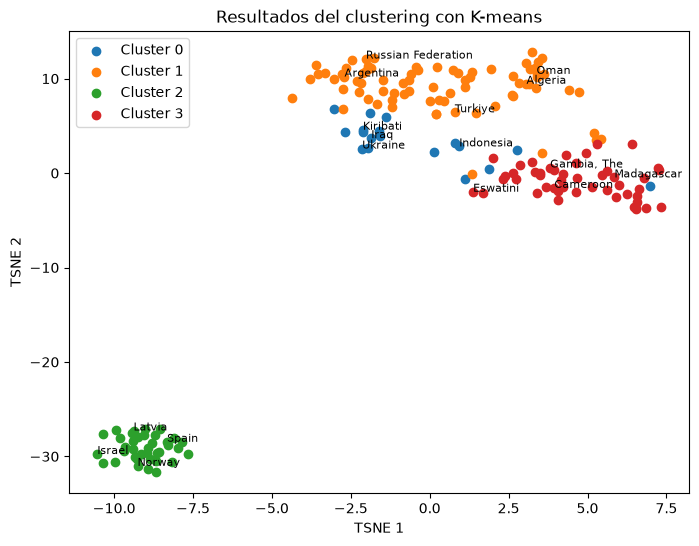

Podemos ver que
- En el cluster 3 se agruparon la mayoria de paises africanos.

- En el cluster 2 tiene un indicio de agrupar los paises desarrollados.

<h3>Inciso b

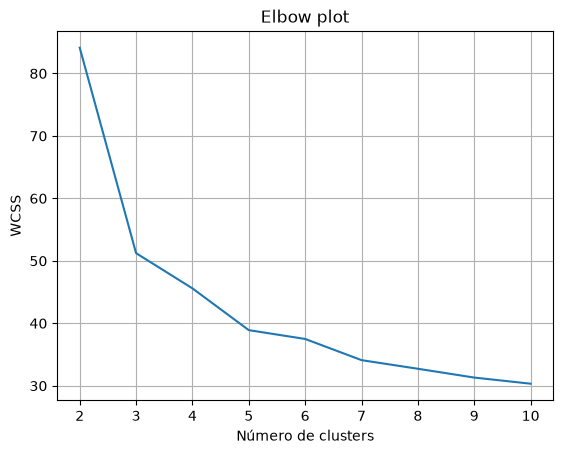

In [12]:
from sklearn.cluster import KMeans, k_means
wcss = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=10)
    kmeans.fit(features_data_2015)
    wcss.append(kmeans.inertia_)

plt.plot(range(2, 11), wcss)
plt.title('Elbow plot')
plt.grid(True)
plt.xlabel('Número de clusters')
plt.ylabel('WCSS')
plt.show()

Tal vez la mejor eleccion de clusters esta dada por 5.

<h3>Inciso c

In [13]:
k = [4, 5, 7]

<h4>Indice de Davies Bouldin

$DB = \frac{1}{k} \sum_{i=1}^{k} \max_{j \neq i} \left( \frac{S_i + S_j}{d_{ij}} \right)$, donde $k$ es el número de clusters, $S_i$ es la dispersión dentro del cluster, que se calcula como $S_i = \frac{1}{|C_i|} \sum_{x \in C_i} \left\| x - c_i \right\|$, y $d_ij$ es la distancia entre los centroides de los clusters $i$ y $j$.

K-means[4]
DB score: 1.2251
Silhouette score: 0.3703
-------------
K-means[5]
DB score: 1.1988
Silhouette score: 0.3881
-------------
K-means[7]
DB score: 1.2239
Silhouette score: 0.3198
-------------


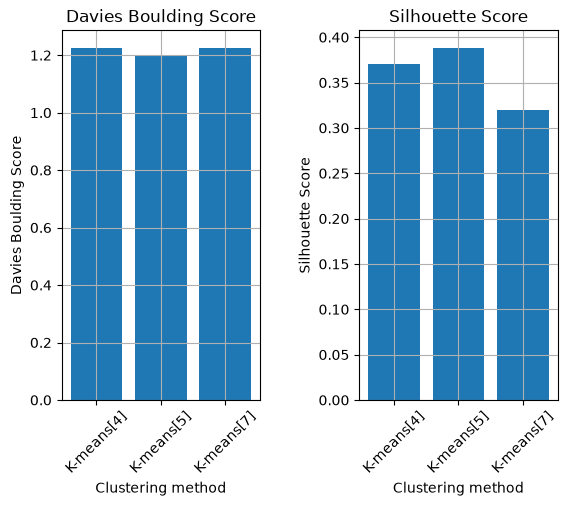

In [14]:
from sklearn.metrics import davies_bouldin_score, silhouette_score
kmean4 = clusterizar(4, features_data_2015)
kmean5 = clusterizar(5, features_data_2015)
kmean7 = clusterizar(7, features_data_2015)

clusters_to_compare = [kmean4, kmean5, kmean7]
clustering_methods = ['K-means[4]', 'K-means[5]', 'K-means[7]']

db_scores = np.zeros(len(clusters_to_compare))
silhouette_scores = np.zeros(len(clusters_to_compare))

for i in range(len(clusters_to_compare)):
    #calculamos metricas
    db_scores[i] = davies_bouldin_score(features_data_2015, clusters_to_compare[i])
    silhouette_scores[i] = silhouette_score(features_data_2015, clusters_to_compare[i])

    print(clustering_methods[i])
    print('DB score: {:,.4f}'.format(db_scores[i]))
    print('Silhouette score: {:.4f}'.format(silhouette_scores[i]))
    print('-------------')

# inicializamos un gráfico para cada métrica
fig, axes = plt.subplots(1, 2)
plt.subplots_adjust(wspace=0.5)

# graficamos el Davies Bouldin score
axes[0].bar(np.arange(db_scores.size), db_scores)
axes[0].set_title('Davies Boulding Score')
axes[0].set_xlabel('Clustering method')
axes[0].set_ylabel('Davies Boulding Score')
axes[0].set_xticks(np.arange(db_scores.size))
axes[0].set_xticklabels(clustering_methods, rotation=45)
axes[0].grid(True)

# y el Silhouette Score
axes[1].bar(np.arange(silhouette_scores.size), silhouette_scores)
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Clustering method')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(np.arange(silhouette_scores.size))
axes[1].set_xticklabels(clustering_methods, rotation=45)
axes[1].grid(True)

plt.show()

Podemos observar que buscar 5 clusters nos da la razon en ambas pruebas, ya que en Davies Boulding Score obtuvimos el menor puntaje y en Silhouette Score obtuvimos el puntaje mas cercano a 1.

<h3>Inciso d

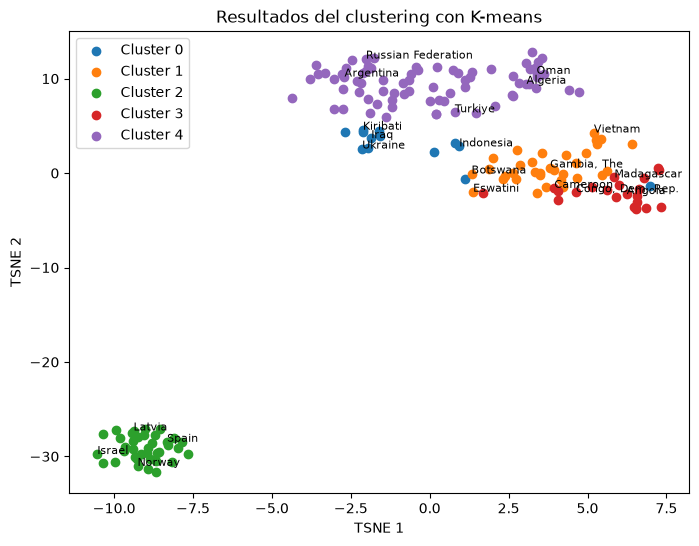

In [15]:
from cProfile import label
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42)
tsne_results = tsne.fit_transform(features_data_2015)
k  = 5
cluster_kmeans = clusterizar(k, features_data_2015)

tsne_df = pd.DataFrame({'x': tsne_results[:, 0], 'y': tsne_results[:, 1], 'Cluster': cluster_kmeans, 'Country': countries})

plt.figure(figsize=(8, 6))
for cluster_num in range(k):
    plt.scatter(tsne_df[tsne_df['Cluster'] == cluster_num]['x'], tsne_df[tsne_df['Cluster'] == cluster_num]['y'], label=f'Cluster {cluster_num}')

    #seleccionar 5 paises a mostrar
    countries_to_label = tsne_df[tsne_df['Cluster'] == cluster_num]['Country'].tolist()
    if 'Argentina' in countries_to_label:
        countries_to_label.remove('Argentina')
        countries_to_label = ['Argentina'] + countries_to_label[:4]
    else:
        countries_to_label = countries_to_label[:4]

    #mostrar los paises
    for country in countries_to_label:
        row = tsne_df[(tsne_df['Cluster'] == cluster_num) & (tsne_df['Country'] == country)]
        if not row.empty:
            plt.text(row['x'].values[0], row['y'].values[0], country, fontsize=8)

plt.xlabel('TSNE 1')
plt.ylabel('TSNE 2')
plt.legend()
plt.title('Resultados del clustering con K-means')
plt.show()

Podemos ver que tiene mucho sentido pudiendo diferenciar claramente entre paises desarrollados y subdesarrollados. Ademas, desde el lado de los paises subdesarrollados, es posible ver los 4 grupos debido a diferencias considerables en cuanto a salud, PBI y escolaridades.

In [18]:
df_cluster.head()

,Cluster,Infant_deaths,Under_five_deaths,Adult_mortality,Alcohol_consumption,Hepatitis_B,Measles,BMI,Polio,Diphtheria,Incidents_HIV,GDP_per_capita,Population_mln,Thinness_ten_nineteen_years,Thinness_five_nine_years,Schooling,Life_expectancy
0,0,26.80,33.25,188.01225,1.835,75.5,65.0,26.3,79.0,77.0,0.17,2852.5,13.610,1.50,1.7,7.35,68.65
1,1,52.25,77.20,286.83050,1.750,85.0,64.0,22.3,85.0,84.0,1.04,941.5,11.120,8.15,8.0,4.30,59.50
2,2,4.10,4.90,80.19225,10.215,91.0,91.0,26.1,96.0,96.0,0.08,33545.0,8.330,1.00,0.9,11.70,79.30
3,3,77.45,118.50,306.35575,1.315,66.0,64.0,22.7,63.0,64.0,0.84,776.0,12.515,8.30,8.2,3.65,55.10
4,4,15.60,18.30,141.43650,3.965,95.0,90.0,26.0,96.0,96.0,0.14,5265.5,5.165,3.30,3.3,8.50,73.10


In [ ]:
cluster_df = pd.DataFrame({'Country': countries, 'Cluster': cluster_kmeans})
cluster_3 = cluster_df[cluster_df['Cluster'] == 3]['Country'].tolist()
cluster_1 = cluster_df[cluster_df['Cluster'] == 1]['Country'].tolist()
cluster_0 = cluster_df[cluster_df['Cluster'] == 0]['Country'].tolist()
cluster_2 = cluster_df[cluster_df['Cluster'] == 2]['Country'].tolist()
cluster_4 = cluster_df[cluster_df['Cluster'] == 4]['Country'].tolist()
country_clusters = [cluster_0, cluster_1, cluster_2, cluster_3, cluster_4]

df_cluster = pd.DataFrame({
    'Cluster': [0, 1, 2, 3, 4]
})
list = []
for i in df.drop(columns=['Developed', 'Year']).select_dtypes(include='number').columns:
    for j in range(len(df_cluster['Cluster'])):
        list.append(df[df['Country'].isin(country_clusters[j])][i].median())
    df_cluster[i] = list
    list.clear()

df_cluster.head()

Cluster 0:
['Ukraine', 'Iraq', 'Indonesia', 'Kiribati', 'Syrian Arab Republic', 'Guatemala', 'Micronesia, Fed. Sts.', 'Papua New Guinea', 'Vanuatu', 'Suriname', 'Philippines', 'Samoa', 'South Africa']

Cluster 1:
['Gambia, The', 'Vietnam', 'Eswatini', 'Botswana', 'Nepal', 'Guinea-Bissau', 'Eritrea', 'India', 'Malawi', 'Myanmar', 'Burundi', 'Mozambique', 'Tanzania', 'Gabon', 'Comoros', 'Uganda', 'Ghana', 'Senegal', 'Congo, Rep.', 'Namibia', 'Zimbabwe', 'Kenya', 'Zambia', 'Bangladesh', 'Rwanda', 'Cambodia', 'Bhutan', 'Lao PDR', 'Togo', 'Burkina Faso', 'Timor-Leste', 'Ethiopia', 'Djibouti']

Cluster 2:
['Spain', 'Norway', 'Latvia', 'Israel', 'New Zealand', 'Sweden', 'Czechia', 'Canada', 'Lithuania', 'Netherlands', 'Bulgaria', 'Portugal', 'Finland', 'Slovenia', 'Belgium', 'Japan', 'Slovak Republic', 'Austria', 'Malta', 'Greece', 'Ireland', 'Croatia', 'Switzerland', 'United Kingdom', 'Germany', 'Denmark', 'Poland', 'Italy', 'Hungary', 'Australia', 'Luxembourg', 'United States', 'Cyprus', 'Iceland', 'Estonia', 'Romania', 'France']

Cluster 3:
['Cameroon', 'Madagascar', 'Congo, Dem. Rep.', 'Angola', 'Chad', 'Guinea', 'Benin', 'Lesotho', 'Sierra Leone', 'Nigeria', 'Pakistan', 'Afghanistan', 'Equatorial Guinea', 'Mauritania', 'Yemen, Rep.', 'Niger', 'Somalia', 'Liberia', 'Central African Republic', 'Haiti', "Cote d'Ivoire", 'Mali']

Cluster 4:
['Turkiye', 'Russian Federation', 'Algeria', 'Oman', 'Belarus', 'Costa Rica', 'Solomon Islands', 'Honduras', 'Dominican Republic', 'Mexico', 'St. Vincent and the Grenadines', 'Brazil', 'Guyana', 'China', 'Kuwait', 'Grenada', 'Albania', 'Saudi Arabia', 'Turkmenistan', 'Antigua and Barbuda', 'Seychelles', 'El Salvador', 'Panama', 'Jordan', 'Azerbaijan', 'Thailand', 'Mongolia', 'Maldives', 'Trinidad and Tobago', 'United Arab Emirates', 'Sao Tome and Principe', 'Belize', 'Lebanon', 'Jamaica', 'Barbados', 'North Macedonia', 'Morocco', 'St. Lucia', 'Colombia', 'Tajikistan', 'Moldova', 'Montenegro', 'Bolivia', 'Kyrgyz Republic', 'Qatar', 'Kazakhstan', 'Serbia', 'Paraguay', 'Bosnia and Herzegovina', 'Brunei Darussalam', 'Armenia', 'Uzbekistan', 'Uruguay', 'Chile', 'Mauritius', 'Singapore', 'Iran, Islamic Rep.', 'Cuba', 'Peru', 'Egypt, Arab Rep.', 'Georgia', 'Bahamas, The', 'Libya', 'Argentina', 'Cabo Verde', 'Ecuador', 'Fiji', 'Sri Lanka', 'Malaysia', 'Tonga', 'Tunisia', 'Venezuela, RB', 'Nicaragua', 'Bahrain']

<h3>Inciso e

In [ ]:
data_2015.head()

In [25]:
data_2015['index_mortality'] = (data_2015['Adult_mortality'] + data_2015['Infant_deaths'] + data_2015['Under_five_deaths']) / 3

In [27]:
data_cluster_1 = data_2015[data_2015['Cluster'] == 1]
data_cluster_3 = data_2015[data_2015['Cluster'] == 3]

In [28]:
data_cluster_13 = data_2015[(data_2015['Cluster'] == 1) | (data_2015['Cluster'] == 3)]

Tenemos la hipotesis de que existe una diferencia significativa en cuanto a medidores de salud entre los paises del cluster 1 y 3.

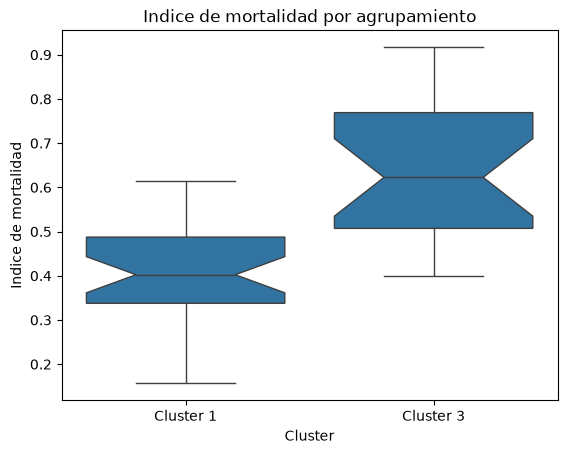

In [32]:
sns.boxplot(x='Cluster', y='index_mortality', data=data_cluster_13, notch=True)
plt.title("Indice de mortalidad por agrupamiento")
plt.xlabel("Cluster")
plt.xticks(ticks=[0, 1], labels=["Cluster 1", "Cluster 3"])
plt.ylabel("Indice de mortalidad")
plt.show()

Podemos ver (graficamente) que si existen diferencias significativas en cuanto al indice de mortalidad entre ambos grupos.

In [33]:
import scipy.stats as stats

<h4>Normalidad

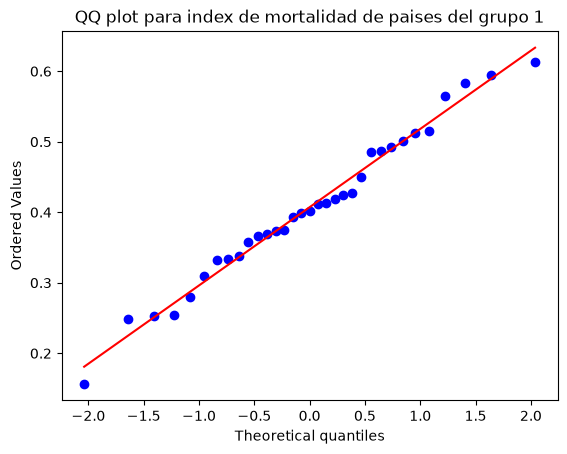

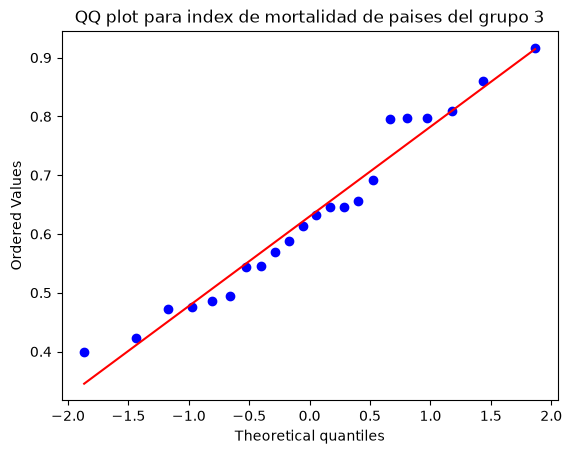

In [35]:
stats.probplot(data_cluster_1['index_mortality'], dist='norm', plot=plt)
plt.title('QQ plot para index de mortalidad de paises del grupo 1')
plt.show()

stats.probplot(data_cluster_3['index_mortality'], dist='norm', plot=plt)
plt.title('QQ plot para index de mortalidad de paises del grupo 3')
plt.show()

A simple vista podemos decir que ninguna de las distribuciones sigue justamente una distribucion normal, probamos estadisticamente

In [36]:
from scipy.stats import shapiro

In [37]:
stat, p = shapiro(data_cluster_1['index_mortality'])
print(f"Test de Shapiro-Wilk para grupo 1: Estadístico={stat:.3f}, p-valor={p:.3f}")

stat, p = shapiro(data_cluster_3['index_mortality'])
print(f"Test de Shapiro-Wilk para grupo 3: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Shapiro-Wilk para grupo 1: Estadístico=0.983, p-valor=0.878
Test de Shapiro-Wilk para grupo 3: Estadístico=0.955, p-valor=0.389


Vemos que tenemos normalidad ya que el p-valor de ambos > 0.05, se comprueba la hipotesis nula

<h4>Homocedasticidad

Usamos el test de Levene que tiene como hipotesis nula la igualdad de varianzas, por lo que si el p-valor es menor a 0.05 las varianzas seran significativamente diferentes.

In [38]:
stat, p = stats.levene(data_cluster_1['index_mortality'], data_cluster_3['index_mortality'])
print(f"Test de Levene para indice de mortalidad: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Levene para indice de mortalidad: Estadístico=3.166, p-valor=0.081


Tenemos igualdad de varianzas entre ambos grupos, vamos a usar T-student

<h4>T-student

In [39]:
t_stadistic, p_value = stats.ttest_ind(data_cluster_1['index_mortality'], data_cluster_3['index_mortality'])
print(f"Test t de Student para indice de mortalidad: Estadístico={t_stadistic:.3f}, p-valor={p_value:.3f}")

alpha = 0.05
if p_value > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una diferencia significativa en el indice de mortalidad entre los clusters 1 y 3.")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe una diferencia significativa en el indice de mortalidad entre los clusters 1 y 3.")

Test t de Student para indice de mortalidad: Estadístico=-6.462, p-valor=0.000
Se rechaza la hipótesis nula.
Existe una diferencia significativa en el indice de mortalidad entre los clusters 1 y 3.
